# Exploratory Data Analysis: Compounding Supply Usage
Synthetic data: 35 supplies, Jan-Dec 2025. Goal: understand usage patterns before setting par levels.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

items = pd.read_csv("../data/items.csv")
usage = pd.read_csv("../data/daily_usage.csv", parse_dates=["date"])
df = usage.merge(items, on="item_id")
print(df.shape)
print(df.isna().sum().sum())   # should print 0

(12775, 9)
0


In [2]:
df["weekday"] = df["date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df.groupby("weekday")["qty_used"].mean().reindex(order).round(1)

weekday
Monday       31.4
Tuesday      29.7
Wednesday    27.8
Thursday     25.3
Friday       23.8
Saturday      0.0
Sunday        0.0
Name: qty_used, dtype: float64

In [3]:
weekly = (df.set_index("date").groupby("item_name")["qty_used"]
            .resample("W-SUN").sum().reset_index())
stats = weekly.groupby("item_name")["qty_used"].agg(["mean", "std"])
stats["cv"] = stats["std"] / stats["mean"]
stats.sort_values("cv", ascending=False).head(10).round(2)

,mean,std,cv
item_name,,,
Dextrose 5% 250 mL bag,47.68,18.60,0.39
Sharps container (chemo),9.64,3.33,0.35
Dextrose 5% 50 mL bag,28.32,9.50,0.34
Syringe 60 mL,69.11,22.48,0.33
Non-PVC IV admin set,86.09,26.51,0.31
CSTD syringe adaptor,231.74,70.43,0.30
CSTD vial adaptor 13 mm,42.62,12.76,0.30
Chemo waste bag,45.57,13.60,0.30
Chemo gown,82.75,24.33,0.29


In [4]:
new = ["Syringe 50 mL", "Dextrose 5% 50 mL bag", "Lactated Ringer's 1000 mL bag",
       "Red caps (syringe tip caps)", "Amber line covers"]
stats.loc[new].round(2)

,mean,std,cv
item_name,,,
Syringe 50 mL,55.75,12.40,0.22
Dextrose 5% 50 mL bag,28.32,9.50,0.34
Lactated Ringer's 1000 mL bag,24.00,6.30,0.26
Red caps (syringe tip caps),192.34,40.87,0.21
Amber line covers,28.77,6.92,0.24


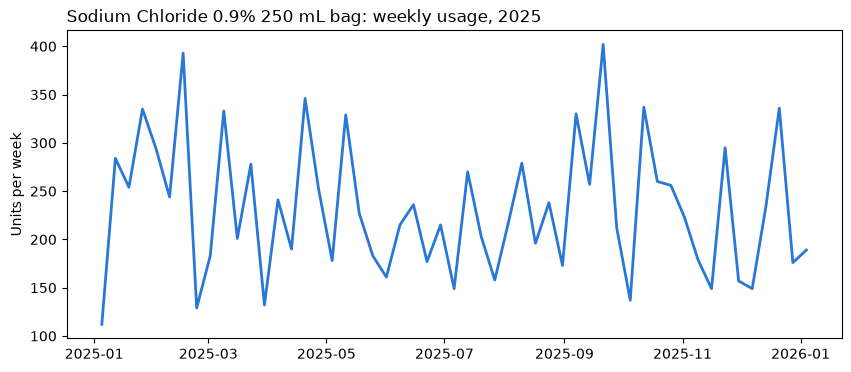

In [5]:
one = weekly[weekly["item_name"] == "CSTD syringe adaptor"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(one["date"], one["qty_used"], color="#2a78d6", linewidth=2)
ax.set_title("Sodium Chloride 0.9% 250 mL bag: weekly usage, 2025", loc="left")
ax.set_ylabel("Units per week")
plt.show()

## Observations
- **Monday is the busiest day.** Average usage per item is about 31.4 units on Monday vs. 23.8 on Friday, roughly 32% higher. Because Monday's order doesn't arrive until Tuesday or later, Monday runs entirely on stock already on the shelf. Par levels need to cover the busiest day, not an average day.

- **Dextrose 5% 250 mL is the least predictable item** (weekly CV 0.39), followed by the chemo sharps container (0.35) and Dextrose 5% 50 mL (0.34). Items like these need more safety stock relative to their average use than steady items do.

- **Reality check against the bench:** in practice, 50 mL and 60 mL syringes are among the most-used supplies, about 200 per week, because many chemo regimens go out on pumps. In this synthetic data they average only about 56 and 69 per week. Red caps run the opposite way: the data shows about 192 per week, but my site uses far fewer. The simulated volumes don't fully match a real infusion center, and I note this as a limitation.

- **Why I measured variability weekly, not daily:** daily data includes weekend and holiday closures, and those zeros are predictable, not random. For 10 mL syringes, daily CV is 0.86 but weekly CV is only 0.20. Using daily numbers would make every item look about four times more unpredictable than it really is and inflate safety stock.

- **Chart note:** the weekly x-axis ends at "2026-01" because each week is labeled by the Sunday it ends on, and the last week of 2025 ends Sunday, January 4, 2026.